# Flight Fare Prediction

## Project Overview

predict the ticket price (Indian Rupee: INR) for historical Indian domestic flights from itinerary details.  


exploratory data analysis → deterministic feature engineering → leakage-aware splitting → model comparison with grouped cross-validation → untouched holdout evaluation → predictions for unlabeled rows.

## Environment

```powershell
conda create -n flight-fare python=3.11 -y
conda activate flight-fare
python -m pip install -r requirements.txt
python -m pip install ipykernel
```

In [12]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_DIR = Path('data')
OUTPUT_DIR = Path('outputs')
TRAIN_FILE = DATA_DIR / 'Data_Train.xlsx'
UNLABELED_FILE = DATA_DIR / 'Test_set.xlsx'
CATEGORICAL_COLUMNS = ['Airline', 'Source', 'Destination', 'Route', 'Additional_Info']

plt.rcParams.update({'figure.figsize': (9, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 30)

assert TRAIN_FILE.exists() and UNLABELED_FILE.exists(), (
    'Data files not found. Start Jupyter from the project root directory.'
)
print('Input files located successfully.')

Input files located successfully.


## Load and Explore the Data

The dataset includes two files:

* Data_Train.xlsx: Contains flight details and actual ticket prices (Price). We use this data to train and evaluate our models.

* Test_set.xlsx: Contains flight details without ticket prices. We use this data to predict prices after training the model.

Since Test_set.xlsx does not contain actual prices, we cannot use it to measure model performance. Instead, we split Data_Train.xlsx into training and testing sets to evaluate how well our model predicts flight prices.

In [13]:
train_df = pd.read_excel(TRAIN_FILE)
unlabeled_df = pd.read_excel(UNLABELED_FILE)

required_features = [
    'Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
    'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'Additional_Info'
]
assert set(required_features + ['Price']).issubset(train_df.columns)
assert set(required_features).issubset(unlabeled_df.columns)
assert 'Price' not in unlabeled_df.columns, 'Do not use an unlabeled file to calculate metrics.'
assert train_df['Price'].notna().all(), 'Prices must be present for supervised learning.'

raw_X = train_df[required_features].copy()
y = train_df['Price'].copy()

print(f'Labeled rows: {len(train_df):,} | Unlabeled rows: {len(unlabeled_df):,}')
print(f'Features: {len(required_features)} | Target: Price (INR)')
display(train_df.head(10))

Labeled rows: 10,683 | Unlabeled rows: 2,671
Features: 10 | Target: Price (INR)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
5,SpiceJet,24/06/2019,Kolkata,Banglore,CCU → BLR,09:00,11:25,2h 25m,non-stop,No info,3873
6,Jet Airways,12/03/2019,Banglore,New Delhi,BLR → BOM → DEL,18:55,10:25 13 Mar,15h 30m,1 stop,In-flight meal not included,11087
7,Jet Airways,01/03/2019,Banglore,New Delhi,BLR → BOM → DEL,08:00,05:05 02 Mar,21h 5m,1 stop,No info,22270
8,Jet Airways,12/03/2019,Banglore,New Delhi,BLR → BOM → DEL,08:55,10:25 13 Mar,25h 30m,1 stop,In-flight meal not included,11087
9,Multiple carriers,27/05/2019,Delhi,Cochin,DEL → BOM → COK,11:25,19:15,7h 50m,1 stop,No info,8625


In [14]:
audit = pd.DataFrame({
    'Missing values': train_df.isna().sum(),
    'Distinct values': train_df.nunique(dropna=True),
})
display(audit)
print('Identical full rows:', train_df.duplicated().sum())
print('Identical feature rows (regardless of price):', raw_X.duplicated().sum())
print('Fare range: INR {:,.0f}–{:,.0f}'.format(y.min(), y.max()))

,Missing values,Distinct values
Airline,0,12
Date_of_Journey,0,44
Source,0,5
Destination,0,6
Route,1,128
Dep_Time,0,222
Arrival_Time,0,1343
Duration,0,368
Total_Stops,1,5
Additional_Info,0,10


Identical full rows: 220
Identical feature rows (regardless of price): 419
Fare range: INR 1,759–79,512


### Data Quality Check Results

- **Missing Values:** Only `Route` and `Total_Stops` have missing values, with 1 missing value each. All other columns have no missing values.
- **Unique Values:** The dataset contains 12 airlines, 5 departure cities, and 6 destination cities.
- **Duplicate Rows:** There are 220 rows with exactly the same values across all columns.
- **Duplicate Features:** There are 419 rows with identical flight details, even when ticket prices are different.
- **Price Range:** Ticket prices range from INR 1,759 to INR 79,512.

The dataset is mostly complete, with only a few missing values. However, it contains duplicate records and a wide range of ticket prices.

Should handle the missing values and consider duplicate flight details when splitting the data into training and testing sets to avoid data leakage. We should also examine the price distribution to better understand unusually high ticket prices.

## Exploratory data analysis (EDA)

This section explores ticket prices and identifies patterns in the dataset.
The original prices are kept, including unusually high prices, as they may represent expensive tickets such as business-class flights.

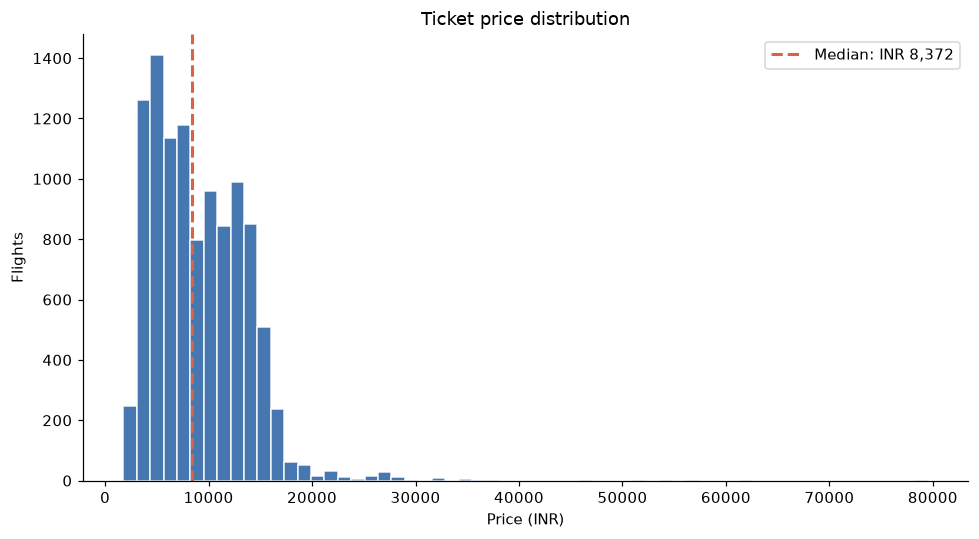

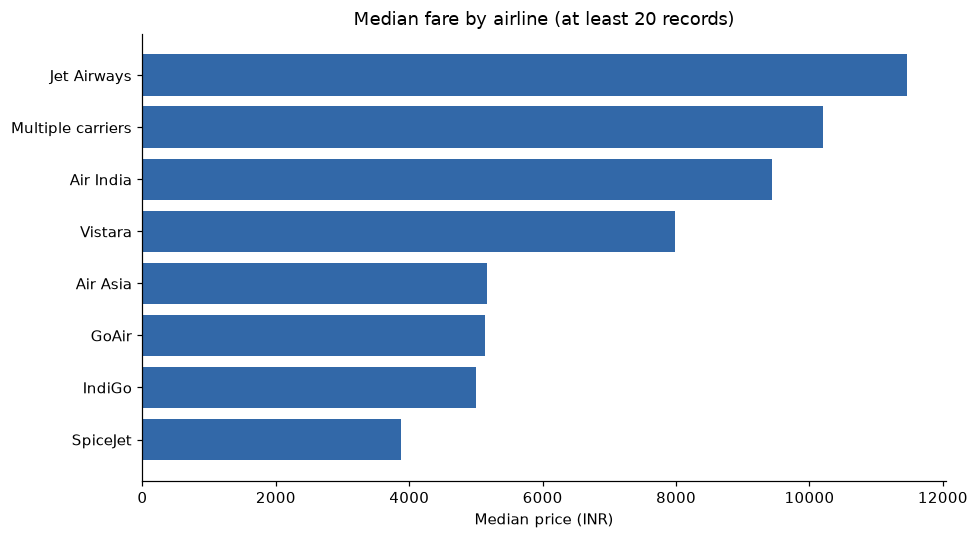

In [15]:
fig, ax = plt.subplots()
ax.hist(y, bins=60, color='#3268A8', edgecolor='white', alpha=0.9)
ax.axvline(y.median(), color='#D76445', ls='--', lw=2,
           label=f'Median: INR {y.median():,.0f}')
ax.set(title='Ticket price distribution', xlabel='Price (INR)', ylabel='Flights')
ax.legend()
plt.tight_layout()
plt.show()

median_by_airline = (
    train_df.groupby('Airline')['Price']
    .agg(['count', 'median'])
    .query('count >= 20')
    .sort_values('median')
)
fig, ax = plt.subplots()
ax.barh(median_by_airline.index, median_by_airline['median'], color='#3268A8')
ax.set(title='Median fare by airline (at least 20 records)', xlabel='Median price (INR)')
plt.tight_layout()
plt.show()

### Key Findings from EDA

**Ticket Price Distribution**
- Most ticket prices are between INR 3,000 and INR 15,000.
- The median ticket price is INR 8,372, meaning half of the tickets cost less than this amount and half cost more.
- The distribution is right-skewed, meaning most tickets have lower prices, while a small number have much higher prices.
- A few unusually expensive tickets appear in the dataset, with prices reaching nearly INR 80,000.

**Median Ticket Price by Airline**

- Jet Airways has the highest median ticket price, followed by Multiple carriers and Air India.
- SpiceJet has the lowest median ticket price among the airlines shown.
- IndiGo, GoAir, and Air Asia have relatively similar median prices.
- Ticket prices vary across airlines, suggesting that the airline may be an important feature for price prediction.

## Feature Engineering

This step converts flight information into useful features for machine learning without using ticket prices (`Price`).

- **Date:** Extract day, month, and weekday from the journey date.
- **Time:** Extract hours and minutes from departure and arrival times.
- **Duration:** Convert flight duration into numerical values.
- **Categorical Data:** Keep airline, route, and other flight details.
- **Missing Values:** Fill missing categories with `Unknown` and missing stop counts with `-1`.

In [16]:
class FlightFeatureBuilder(BaseEstimator, TransformerMixin):
    """Build numeric and categorical flight features without using the target."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        features = pd.DataFrame(index=X.index)

        for col in CATEGORICAL_COLUMNS:
            features[col] = X[col].fillna('Unknown').astype(str).str.strip()

        journey_date = pd.to_datetime(
            X['Date_of_Journey'], format='%d/%m/%Y', errors='coerce'
        )
        features['journey_day'] = journey_date.dt.day.fillna(-1).astype('int16')
        features['journey_month'] = journey_date.dt.month.fillna(-1).astype('int16')
        features['journey_weekday'] = journey_date.dt.dayofweek.fillna(-1).astype('int16')
        features['journey_week'] = (
            journey_date.dt.isocalendar().week.fillna(0).astype('int16')
        )

        for col, prefix in [('Dep_Time', 'departure'), ('Arrival_Time', 'arrival')]:
            time_parts = X[col].astype('string').str.extract(r'(\d{1,2}):(\d{2})')
            features[f'{prefix}_hour'] = (
                pd.to_numeric(time_parts[0], errors='coerce').fillna(-1).astype('int16')
            )
            features[f'{prefix}_minute'] = (
                pd.to_numeric(time_parts[1], errors='coerce').fillna(-1).astype('int16')
            )

        duration_parts = X['Duration'].astype('string').str.extract(
            r'(?:(\d+)\s*h)?\s*(?:(\d+)\s*m)?'
        )
        hours = pd.to_numeric(duration_parts[0], errors='coerce').fillna(0)
        minutes = pd.to_numeric(duration_parts[1], errors='coerce').fillna(0)
        features['duration_min'] = (hours * 60 + minutes).astype('int32')
        features['duration_hr'] = hours.astype('int16')

        stops = pd.to_numeric(
            X['Total_Stops'].astype('string').str.extract(r'(\d+)')[0],
            errors='coerce',
        )
        features['stops'] = (
            stops.mask(X['Total_Stops'].eq('non-stop'), 0).fillna(-1).astype('int16')
        )
        features['is_weekend'] = features['journey_weekday'].isin([5, 6]).astype('int16')
        # # Group departure times into 4-hour intervals (0–5).
        features['departure_time_bin'] = (features['departure_hour'] // 4).astype('int16')
        # # Calculate the arrival hour by adding flight duration to departure time.
        # Use % 24 to keep the hour between 0 and 23.
        features['travel_end_hour'] = (
            (features['departure_hour'] * 60 + features['departure_minute']
             + features['duration_min']) // 60 % 24
        ).astype('int16')
        return features

feature_example = FlightFeatureBuilder().transform(raw_X.head(3))
assert not feature_example.isna().any().any()
display(feature_example)

,Airline,Source,Destination,Route,Additional_Info,journey_day,journey_month,journey_weekday,journey_week,departure_hour,departure_minute,arrival_hour,arrival_minute,duration_min,duration_hr,stops,is_weekend,departure_time_bin,travel_end_hour
0,IndiGo,Banglore,New Delhi,BLR → DEL,No info,24,3,6,12,22,20,1,10,170,2,0,1,5,1
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,No info,1,5,2,18,5,50,13,15,445,7,2,0,1,13
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,No info,9,6,6,23,9,25,4,25,1140,19,2,1,2,4


## Create a Holdout Test Set

* The dataset is split into 80% for training and 20% for testing.
* A group-aware split is used to prevent identical flight details from appearing in both sets. This helps reduce data leakage and provides a more reliable model evaluation.
* The test set is kept separate and used only after selecting the best model.

In [17]:
# Give the same group ID to flights with identical details (excluding Price).
row_groups = pd.util.hash_pandas_object(raw_X.fillna('MISSING').astype(str), index=False)
# Split data into training and testing sets (80/20).
# Keep flights with identical details in the same set.
outer_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
# Get the row positions for each set.
train_idx, test_idx = next(outer_split.split(raw_X, y, groups=row_groups))
# Separate flight features (X) and ticket prices (y) into two sets.
X_train, X_holdout = raw_X.iloc[train_idx].copy(), raw_X.iloc[test_idx].copy()
y_train, y_holdout = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
# Store group IDs to check for overlapping groups later.
train_groups = row_groups.iloc[train_idx]
holdout_groups = row_groups.iloc[test_idx]

assert set(train_groups).isdisjoint(set(holdout_groups))
assert len(X_train) + len(X_holdout) == len(train_df)
print(f'Training: {len(X_train):,} rows | Holdout: {len(X_holdout):,} rows')

Training: 8,560 rows | Holdout: 2,123 rows


## Model Comparison Using Cross-Validation

- **Models:** Median Baseline, Ridge Regression, Decision Tree, Random Forest, and XGBoost.
- **Cross-Validation:** Each model is evaluated using the same 3 group-aware splits from the training data to reduce data leakage.
- **MAE (Main Metric):** Measures the average prediction error in INR. Lower is better.
- **R² (Secondary Metric):** Measures how well the model explains differences in ticket prices.
- **One-Hot Encoding:** Converts categorical features into numbers using only the training data in each fold.

The model with the lowest average MAE is selected for final evaluation on the holdout test set.

In [18]:
NUMERIC_COLUMNS = [col for col in feature_example.columns if col not in CATEGORICAL_COLUMNS]

def encoded_pipeline(regressor, scale_numeric=False):
    numeric_step = StandardScaler() if scale_numeric else 'passthrough'
    encoder = ColumnTransformer([
        ('categorical', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL_COLUMNS),
        ('numeric', numeric_step, NUMERIC_COLUMNS),
    ])
    return Pipeline([
        ('features', FlightFeatureBuilder()),
        ('encode', encoder),
        ('model', regressor),
    ])

candidate_models = {
    # Baseline model
    'Median baseline': encoded_pipeline(DummyRegressor(strategy='median')),
    # Linear regression with regularization
    'Ridge regression': encoded_pipeline(Ridge(alpha=10), scale_numeric=True),
    # Random Forest
    'Random Forest': encoded_pipeline(RandomForestRegressor(n_estimators=160, min_samples_leaf=2, max_features=0.9, random_state=RANDOM_STATE, n_jobs=2,)),
    # Decision Tree
    'Decision Tree': encoded_pipeline(DecisionTreeRegressor(max_depth=14, min_samples_leaf=3, random_state=RANDOM_STATE,)),
    # XGBoost
    'XGBoost': encoded_pipeline(XGBRegressor(
            objective='reg:squarederror',
            n_estimators=650,
            learning_rate=0.04,
            max_depth=8,
            subsample=0.9,
            colsample_bytree=0.9,
            min_child_weight=2,
            reg_lambda=2.0,
            tree_method='hist',
            random_state=RANDOM_STATE,
            n_jobs=2,
        )
    ),
}

cv_splits = list(GroupShuffleSplit(n_splits=5, test_size=0.20, random_state=17).split(X_train, y_train, groups=train_groups))
for fold_train, fold_val in cv_splits:
    assert set(train_groups.iloc[fold_train]).isdisjoint(set(train_groups.iloc[fold_val]))

cv_records = []
for name, template in candidate_models.items():
    for fold_number, (fold_train, fold_val) in enumerate(cv_splits, start=1):
        estimator = clone(template)
        estimator.fit(X_train.iloc[fold_train], y_train.iloc[fold_train])
        predictions = estimator.predict(X_train.iloc[fold_val])
        cv_records.append({
            'Model': name,
            'Fold': fold_number,
            'MAE': mean_absolute_error(y_train.iloc[fold_val], predictions),
            'R2': r2_score(y_train.iloc[fold_val], predictions),
        })
    print(f'Completed group CV: {name}')

cv_results = pd.DataFrame(cv_records)
cv_summary = (
    cv_results.groupby('Model', as_index=False)
    .agg(CV_MAE=('MAE', 'mean'), MAE_SD=('MAE', 'std'), CV_R2=('R2', 'mean'))
    .sort_values('CV_MAE').reset_index(drop=True)
)
display(cv_summary.round(3))

Completed group CV: Median baseline
Completed group CV: Ridge regression
Completed group CV: Random Forest
Completed group CV: Decision Tree
Completed group CV: XGBoost


,Model,CV_MAE,MAE_SD,CV_R2
0,Random Forest,647.614,9.833,0.891
1,XGBoost,656.159,14.264,0.916
2,Decision Tree,817.343,40.583,0.836
3,Ridge regression,1593.261,35.518,0.718
4,Median baseline,3620.397,41.558,-0.027


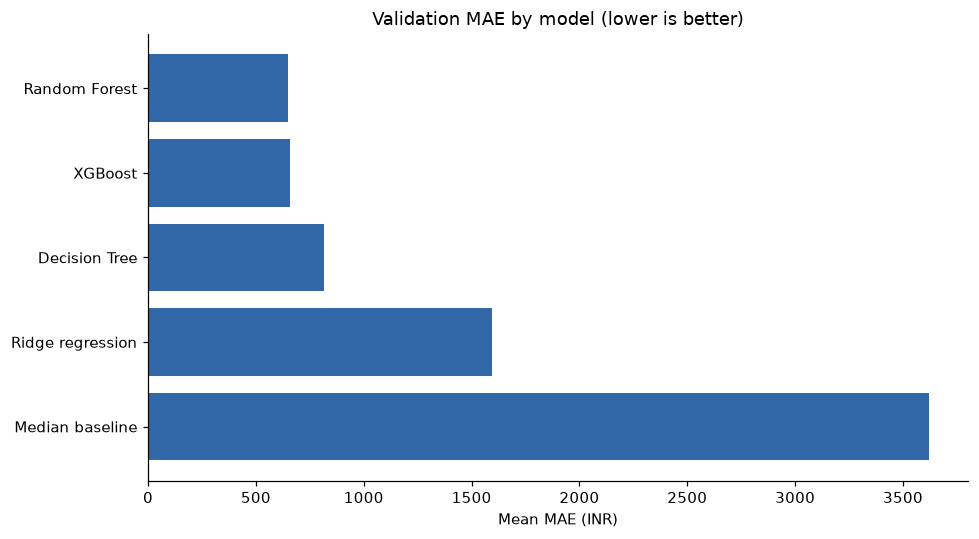

In [19]:
fig, ax = plt.subplots()
view = cv_summary.sort_values('CV_MAE', ascending=False)
ax.barh(view['Model'], view['CV_MAE'], color='#3268A8')
ax.set(title='Validation MAE by model (lower is better)', xlabel='Mean MAE (INR)')
plt.tight_layout()
plt.show()

### Model Comparison Results

- **Random Forest** has the lowest MAE (around 650 INR), making it the best-performing model in this comparison.
- **XGBoost** performs slightly worse than Random Forest, with an MAE of around 660 INR.
- **Decision Tree** has a higher prediction error than Random Forest and XGBoost.
- **Ridge Regression** and **Median Baseline** have much higher errors, making them less suitable for this dataset.

Random Forest is selected as the best model based on its lowest average validation MAE.

## Final Model Evaluation

The model with the lowest average MAE from cross-validation is selected as the best model.
The selected model is then trained again using the full training set and evaluated on the holdout test set.

- **MAE:** Measures the average prediction error.
- **RMSE:** Measures prediction errors, giving more weight to larger errors.
- **R²:** Measures how well the model explains differences in ticket prices.

In [20]:
selected_name = cv_summary.iloc[0]['Model']
selected_pipeline = clone(candidate_models[selected_name])
selected_pipeline.fit(X_train, y_train)
holdout_pred = selected_pipeline.predict(X_holdout)

holdout_metrics = {
    'MAE (INR)': mean_absolute_error(y_holdout, holdout_pred),
    'RMSE (INR)': np.sqrt(mean_squared_error(y_holdout, holdout_pred)),
    'R2': r2_score(y_holdout, holdout_pred),
}
print('Selected by group CV:', selected_name)
for metric, value in holdout_metrics.items():
    print(f'{metric}: {value:,.4f}')

Selected by group CV: Random Forest
MAE (INR): 601.0060
RMSE (INR): 1,630.2024
R2: 0.8787


## 8. Error analysis and interpretability

A strong overall score can conceal errors on expensive tickets. Inspect the prediction scatterplot, the distribution of residuals, and MAE by price segment. These analyses are **diagnostic only**; the test set is not used to adjust the model.

,Flights,MAE_INR
Fare_segment,,
"(1964.999, 6297.0]",709,342.45
"(6297.0, 10844.0]",738,595.39
"(10844.0, 57209.0]",676,878.31


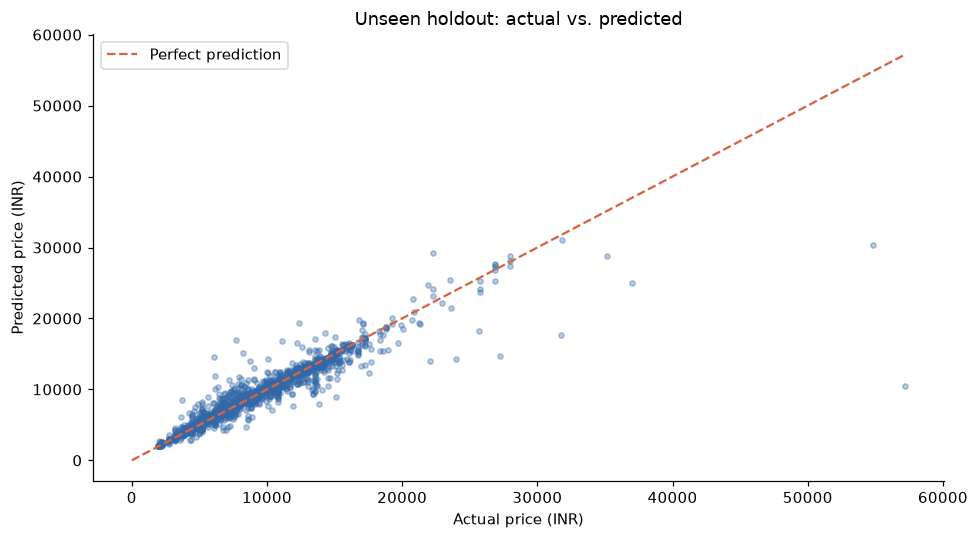

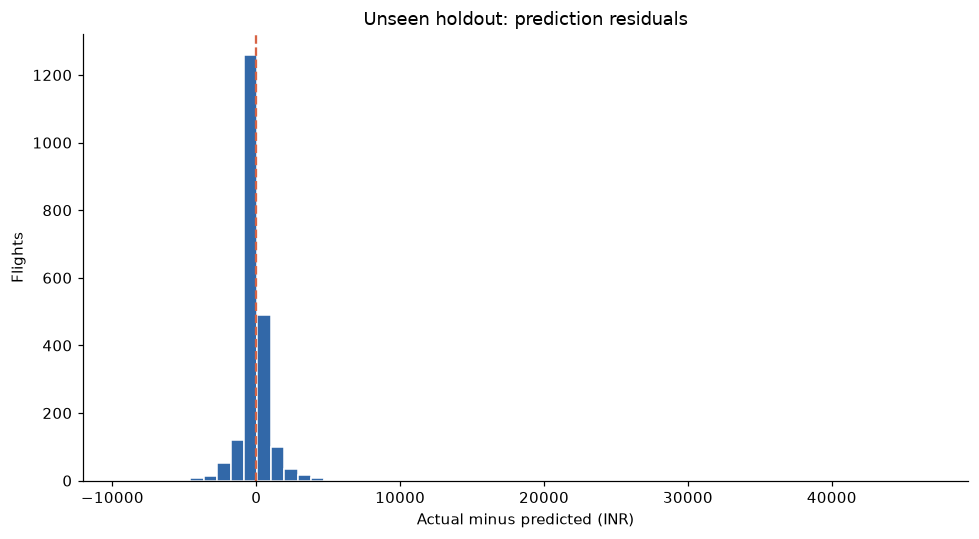

In [21]:
error_table = pd.DataFrame({
    'Actual': y_holdout.to_numpy(),
    'Predicted': holdout_pred,
})
error_table['Absolute_error'] = (error_table['Actual'] - error_table['Predicted']).abs()
error_table['Residual'] = error_table['Actual'] - error_table['Predicted']
error_table['Fare_segment'] = pd.qcut(
    error_table['Actual'], q=3, duplicates='drop'
)
segment_summary = (
    error_table.groupby('Fare_segment', observed=True)
    .agg(Flights=('Absolute_error', 'size'), MAE_INR=('Absolute_error', 'mean'))
)
display(segment_summary.round(2))

fig, ax = plt.subplots()
ax.scatter(error_table['Actual'], error_table['Predicted'],
           s=12, alpha=0.35, color='#3268A8')
range_max = max(error_table['Actual'].max(), error_table['Predicted'].max())
ax.plot([0, range_max], [0, range_max], '--', color='#D76445', label='Perfect prediction')
ax.set(title='Unseen holdout: actual vs. predicted',
       xlabel='Actual price (INR)', ylabel='Predicted price (INR)')
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.hist(error_table['Residual'], bins=60, color='#3268A8', edgecolor='white')
ax.axvline(0, color='#D76445', ls='--')
ax.set(title='Unseen holdout: prediction residuals',
       xlabel='Actual minus predicted (INR)', ylabel='Flights')
plt.tight_layout()
plt.show()

### Error Analysis Results
**Actual vs. Predicted Prices**
- Most predictions are close to the red dashed line, showing that the model predicts most ticket prices reasonably well.
- The model performs better for common ticket prices, especially below INR 20,000.
- Some expensive tickets have predictions far below their actual prices, showing that the model struggles with very high fares.

**Prediction Residuals**
- Most residuals are close to zero, indicating that most prediction errors are relatively small.
- Negative residuals are more common than positive residuals, suggesting that the model tends to slightly overestimate ticket prices.
- A few large positive residuals show that the model significantly underestimates some ticket prices.

The model tends to overestimate prices more often, but some predictions are much lower than the actual prices.

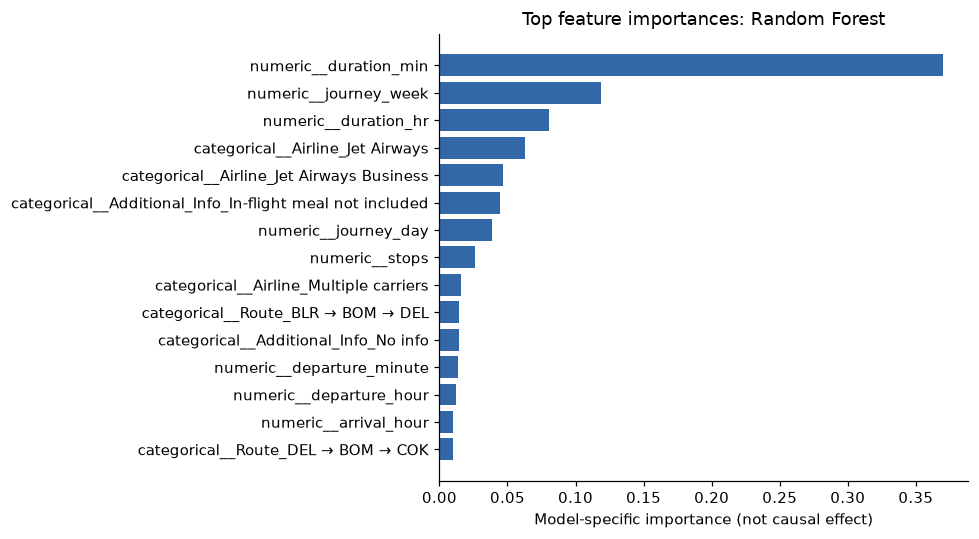

In [22]:
trained_model = selected_pipeline.named_steps['model']
if hasattr(trained_model, 'feature_importances_'):
    if 'encode' in selected_pipeline.named_steps:
        names = selected_pipeline.named_steps['encode'].get_feature_names_out()
    else:
        names = selected_pipeline.named_steps['features'].transform(X_train.head(2)).columns
    importance = (
        pd.DataFrame({'Feature': names,
                      'Importance': trained_model.feature_importances_})
        .sort_values('Importance', ascending=False).head(15)
        .sort_values('Importance')
    )
    fig, ax = plt.subplots()
    ax.barh(importance['Feature'], importance['Importance'], color='#3268A8')
    ax.set(title=f'Top feature importances: {selected_name}',
           xlabel='Model-specific importance (not causal effect)')
    plt.tight_layout()
    plt.show()
else:
    print('The selected estimator has no built-in tree feature importances.')

### Feature Importance Analysis

- **numeric__duration_min** is the most important feature for predicting ticket prices.
- **numeric__journey_week** and **numeric__duration_hr** also have a strong influence on the model's predictions.
- Other features, such as categorical__Route_DEL → BOM → COK and numeric__arrival_hour, have lower importance.

### Feature Descriptions

| Feature | Description |
|---|---|
| `numeric__duration_min` | Total flight duration in minutes. |
| `numeric__journey_week` | Week number of the year when the flight takes place. |
| `numeric__duration_hr` | Flight duration in whole hours. |
| `categorical__Airline_Jet Airways` | Indicates whether the airline is Jet Airways. |
| `categorical__Airline_Jet Airways Business` | Indicates whether the airline category is Jet Airways Business. |
| `categorical__Additional_Info_In-flight meal not included` | Indicates whether the ticket excludes in-flight meals. |
| `numeric__journey_day` | Day of the month when the flight takes place. |
| `numeric__stops` | Number of stops during the journey. |
| `categorical__Airline_Multiple carriers` | Indicates whether the flight involves multiple airlines. |
| `categorical__Route_BLR → BOM → DEL` | Flight route from Bengaluru to Delhi via Mumbai. |
| `categorical__Additional_Info_No info` | Indicates that the dataset provides no additional flight information. |
| `numeric__departure_minute` | Minute part of the departure time (0–59). |
| `numeric__departure_hour` | Hour of departure (0–23). |
| `numeric__arrival_hour` | Hour of arrival (0–23). |
| `categorical__Route_DEL → BOM → COK` | Flight route from Delhi to Kochi via Mumbai. |

## Predict Unlabeled Data

- The model predicts prices without retraining.
- Model accuracy cannot be measured because actual prices are unavailable.
- Predictions are saved to `outputs/test_set_predictions.csv`.

The output file is excluded from Git using `.gitignore`.

In [24]:
external_features = unlabeled_df[required_features].copy()
external_predictions = selected_pipeline.predict(external_features)

prediction_frame = pd.DataFrame({'Price': np.maximum(external_predictions, 0.0)})
assert len(prediction_frame) == len(unlabeled_df)
assert prediction_frame['Price'].notna().all()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_file = OUTPUT_DIR / 'test_set_predictions.csv'
prediction_frame.to_csv(output_file, index=False)
print(f'Saved {len(prediction_frame):,} unlabeled predictions to {output_file}')
display(prediction_frame.head(10))

Saved 2,671 unlabeled predictions to outputs\test_set_predictions.csv


,Price
0,14713.702083
1,4394.295461
2,12898.000000
3,11916.402262
4,3589.778854
5,10264.953125
6,9575.268214
7,4904.137773
8,4772.094462
9,14757.729167
